<a href="https://colab.research.google.com/github/panuza1/deep-learn-project-group/blob/main/DL_mango_leaf_disease_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Import Libraries

In [ ]:
import os
import random
import numpy as np
import pandas as pd

from pathlib import Path
from PIL import Image

from sklearn.model_selection import train_test_split

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

2. Download Dataset

ดาวน์โหลด Mango Leaf Disease Dataset จาก Kaggle

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("aryashah2k/mango-leaf-disease-dataset")

print("Path to dataset files:", path)

100%|██████████| 103M/103M [00:00<00:00, 216MB/s] 

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/aryashah2k/mango-leaf-disease-dataset/versions/1


3. Explore Dataset

ตรวจสอบโครงสร้าง Folder และจำนวนภาพในแต่ละ Class ก่อนนำไปใช้งาน

In [ ]:
data_dir = Path(path)

# Display folders
for folder in data_dir.iterdir():
    if folder.is_dir():
        images = list(folder.glob("*"))
        print(folder.name, ":", len(images), "images")

Powdery Mildew : 500 images
Gall Midge : 500 images
Cutting Weevil : 500 images
Sooty Mould : 500 images
Die Back : 500 images
Anthracnose : 500 images
Bacterial Canker : 500 images
Healthy : 500 images


4. Collect Image Paths and Labels

รวบรวมตำแหน่งไฟล์ภาพและ Label ของแต่ละภาพ โดยกำหนดให้แต่ละ Folder เป็นหนึ่ง Class

In [ ]:
# Supported image formats
image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

image_paths = []
labels = []

class_names = sorted([
    folder.name for folder in data_dir.iterdir()
    if folder.is_dir()
])

print("Classes:", class_names)
print("Number of classes:", len(class_names))

# Collect images
for class_name in class_names:
    class_dir = data_dir / class_name

    for img_path in class_dir.rglob("*"):
        if img_path.suffix.lower() in image_extensions:
            image_paths.append(str(img_path))
            labels.append(class_name)

# Create DataFrame
df = pd.DataFrame({
    "image_path": image_paths,
    "label": labels
})

print("Total images:", len(df))
print(df["label"].value_counts())

Classes: ['Anthracnose', 'Bacterial Canker', 'Cutting Weevil', 'Die Back', 'Gall Midge', 'Healthy', 'Powdery Mildew', 'Sooty Mould']
Number of classes: 8
Total images: 4000
label
Anthracnose         500
Bacterial Canker    500
Cutting Weevil      500
Die Back            500
Gall Midge          500
Healthy             500
Powdery Mildew      500
Sooty Mould         500
Name: count, dtype: int64


5. Split Dataset (train 70% : validation 15% : test 15%)

ใช้ train_test_split() จาก Scikit-learn โดยกำหนด stratify เพื่อรักษาสัดส่วนของแต่ละ Class

In [ ]:
# Set random seed
SEED = 42

# Split Train (70%) and Temporary (30%)
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=SEED
)

# Split Validation (15%) and Test (15%)
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED
)

# Reset index
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

for name, data in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name} Distribution:")
    print(data["label"].value_counts())

Train: 2800
Validation: 600
Test: 600

Train Distribution:
label
Gall Midge          350
Healthy             350
Die Back            350
Anthracnose         350
Cutting Weevil      350
Sooty Mould         350
Powdery Mildew      350
Bacterial Canker    350
Name: count, dtype: int64

Validation Distribution:
label
Die Back            75
Gall Midge          75
Bacterial Canker    75
Healthy             75
Sooty Mould         75
Cutting Weevil      75
Powdery Mildew      75
Anthracnose         75
Name: count, dtype: int64

Test Distribution:
label
Die Back            75
Healthy             75
Powdery Mildew      75
Cutting Weevil      75
Anthracnose         75
Gall Midge          75
Sooty Mould         75
Bacterial Canker    75
Name: count, dtype: int64


6. Image Preprocessing and Data Augmentation

เตรียมภาพให้มีขนาดเท่ากันที่ 224 × 224 pixels เพื่อให้สามารถนำเข้า GoogLeNet ได้

นอกจากนี้จะใช้ Data Augmentation เฉพาะ Training Set เพื่อเพิ่มความหลากหลายของข้อมูล โดยไม่เปลี่ยนแปลงข้อมูลที่ใช้ประเมินประสิทธิภาพ

Training Transform
- Resize และ Crop ภาพให้มีขนาด 224 × 224
- Random Horizontal Flip
- Random Rotation
- Color Jitter
- Normalize ภาพด้วย ImageNet Mean และ Standard Deviation

Validation และ Test Transform
- Resize ภาพ
- Center Crop
- Normalize ภาพ

In [ ]:
# ImageNet normalization
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

# Training transformations
train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Validation and Test transformations
test_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

7. Create Custom Dataset

สร้าง Custom Dataset เพื่อให้ PyTorch สามารถอ่านภาพและแปลง Label เป็นตัวเลขได้

In [ ]:
class MangoLeafDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe
        self.transform = transform

        self.class_to_idx = {
            name: idx
            for idx, name in enumerate(class_names)
        }

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        img_path = self.dataframe.iloc[index]["image_path"]
        label = self.dataframe.iloc[index]["label"]

        # Load image
        image = Image.open(img_path).convert("RGB")

        # Apply transformations
        if self.transform:
            image = self.transform(image)

        # Convert label to number
        label = self.class_to_idx[label]

        return image, label

8. Create Dataset and DataLoader

สร้าง Dataset แยกเป็น 3 ชุด ได้แก่ Train, Validation และ Test

In [ ]:
# Create datasets
train_dataset = MangoLeafDataset(
    train_df,
    transform=train_transform
)

val_dataset = MangoLeafDataset(
    val_df,
    transform=test_transform
)

test_dataset = MangoLeafDataset(
    test_df,
    transform=test_transform
)

# Create DataLoaders
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

9. Check Prepared Data

ตรวจสอบว่าข้อมูลสามารถนำเข้าโมเดลได้ถูกต้องหรือไม่

In [ ]:
# Get one batch
images, labels = next(iter(train_loader))

print("Image shape:", images.shape)
print("Label shape:", labels.shape)

print("Classes:", class_names)
print("Number of classes:", len(class_names))

Image shape: torch.Size([32, 3, 224, 224])
Label shape: torch.Size([32])
Classes: ['Anthracnose', 'Bacterial Canker', 'Cutting Weevil', 'Die Back', 'Gall Midge', 'Healthy', 'Powdery Mildew', 'Sooty Mould']
Number of classes: 8


10. Visualize Sample Images

ลองแสดงภาพตัวอย่างหลังผ่าน Preprocessing เพื่อดูว่าภาพถูกแปลงอย่างถูกต้องหรือไม่

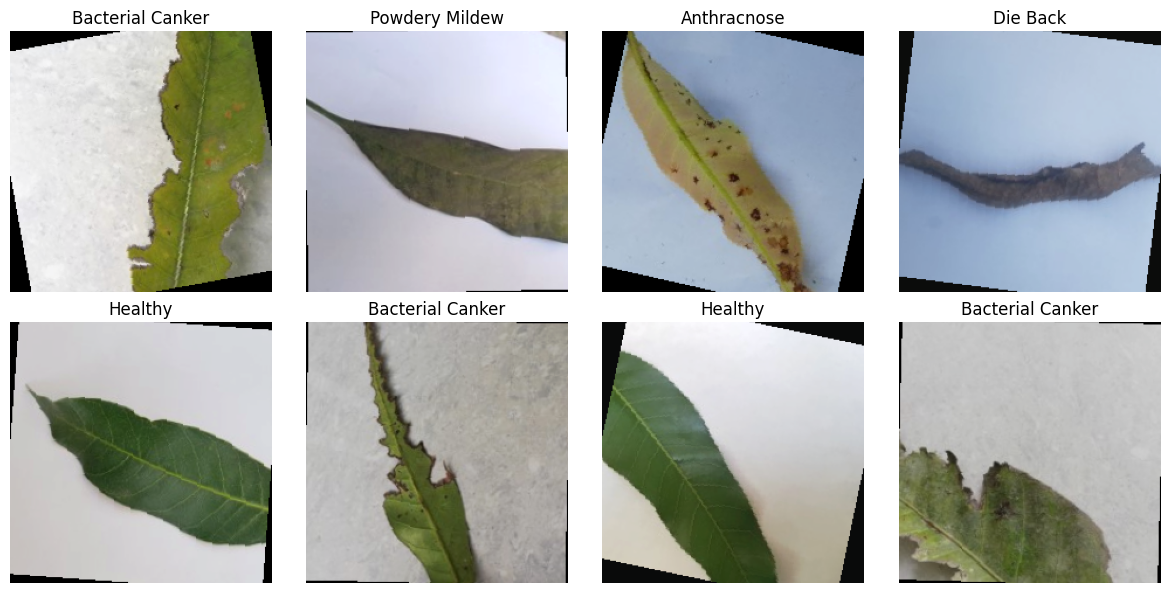

In [ ]:
import matplotlib.pyplot as plt

images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):

    # Reverse normalization
    img = images[i].permute(1, 2, 0).numpy()
    img = img * np.array(std) + np.array(mean)
    img = np.clip(img, 0, 1)

    ax.imshow(img)
    ax.set_title(class_names[labels[i].item()])
    ax.axis("off")

plt.tight_layout()
plt.show()

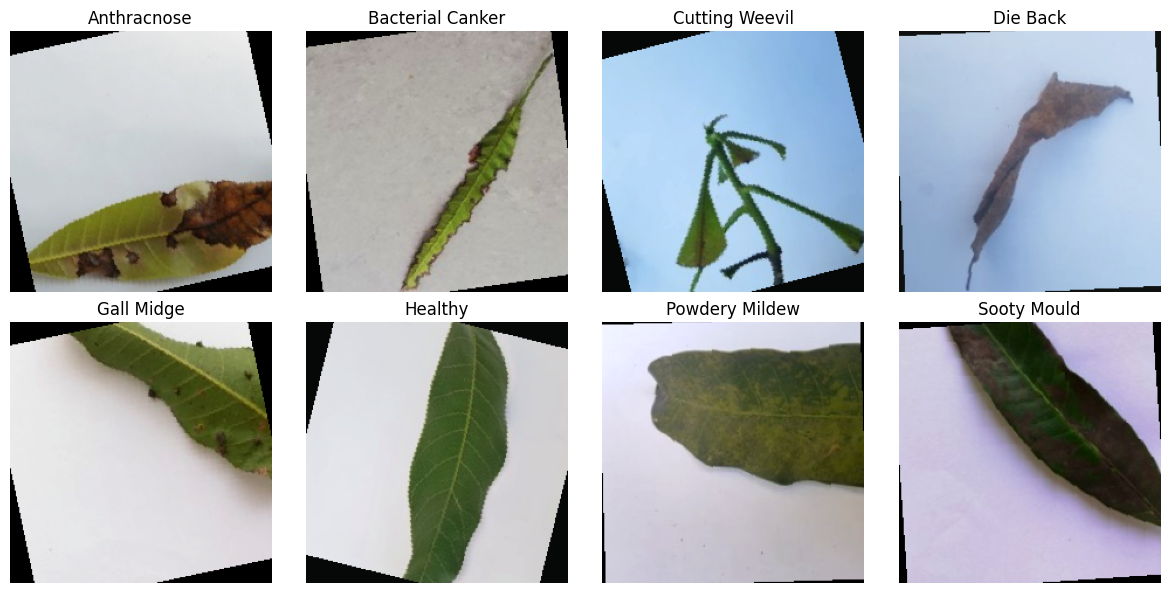

In [ ]:
import math
import matplotlib.pyplot as plt
import numpy as np

# 1. เก็บภาพตัวอย่างคลาสละ 1 ภาพ
class_images = {}
num_classes = len(class_names)

for images, labels in train_loader:
    for img, label in zip(images, labels):
        label_idx = label.item()
        if label_idx not in class_images:
            class_images[label_idx] = img

    # หยุดวนลูปทันทีเมื่อเก็บครบทุกคลาสแล้ว
    if len(class_images) == num_classes:
        break

# 2. จัดขนาดตาราง (Grid) อัตโนมัติตามจำนวนคลาส (กำหนดไว้ที่ 4 คอลัมน์)
cols = 4
rows = math.ceil(num_classes / cols)
fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3 * rows))
axes = axes.flatten()  # แปลงเป็น 1 มิติเพื่อให้ง่ายต่อการวนลูป

# 3. แสดงผลเรียงตามลำดับคลาส (0, 1, 2, ...)
for i in range(len(axes)):
    ax = axes[i]
    if i in class_images:
        # Reverse normalization
        img = class_images[i].permute(1, 2, 0).numpy()
        img = img * np.array(std) + np.array(mean)
        img = np.clip(img, 0, 1)

        ax.imshow(img)
        ax.set_title(class_names[i])
    ax.axis("off")  # ซ่อนแกนทั้งหมด รวมถึงช่องที่ว่าง (ถ้าจำนวนคลาสหาร 4 ไม่ลงตัว)

plt.tight_layout()
plt.show()


11. Load External Dataset (Google Drive)

In [ ]:
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# =====================================
# External Dataset Preparation
# =====================================

from pathlib import Path

# Set External Dataset Path
external_dir = Path(
    "/content/drive/MyDrive/Mango_Dataset/External_Test"
)

# Check folder
if not external_dir.exists():
    raise FileNotFoundError(
        f"External Dataset not found: {external_dir}"
    )

# Collect External Images
external_paths = []
external_labels = []

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

for class_name in class_names:

    class_dir = external_dir / class_name

    if not class_dir.exists():
        print(f"Warning: Missing folder {class_name}")
        continue

    for img_path in class_dir.rglob("*"):

        if img_path.suffix.lower() in image_extensions:

            external_paths.append(str(img_path))
            external_labels.append(class_name)


# Create External DataFrame
external_df = pd.DataFrame({
    "image_path": external_paths,
    "label": external_labels
})

# Check External Dataset
print("Total External Images:", len(external_df))

print("\nExternal Class Distribution:")
print(
    external_df["label"].value_counts()
)

Mounted at /content/drive


FileNotFoundError: External Dataset not found: /content/drive/MyDrive/Mango_Dataset/External_Test

12. Create External Test DataLoader

ใช้ Custom Dataset และ Transform เดิมเลย

In [ ]:
external_dataset = MangoLeafDataset(
    external_df,
    transform=test_transform
)

external_loader = DataLoader(
    external_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("External Test Dataset Ready!")
print("Total Images:", len(external_dataset))

External Test Dataset Ready!
Total Images: 80


13. Check and Visualize Prepared Data

ส่วนนี้ช่วยตรวจสอบว่า Original Dataset และ External Dataset โหลดได้ครบหรือไม่ และตรวจสอบว่าภาพจาก Google Drive โหลดและแสดงผลถูกต้องไหม

         Dataset  Total Images
0          Train          2800
1     Validation           600
2  Internal Test           600
3  External Test            80


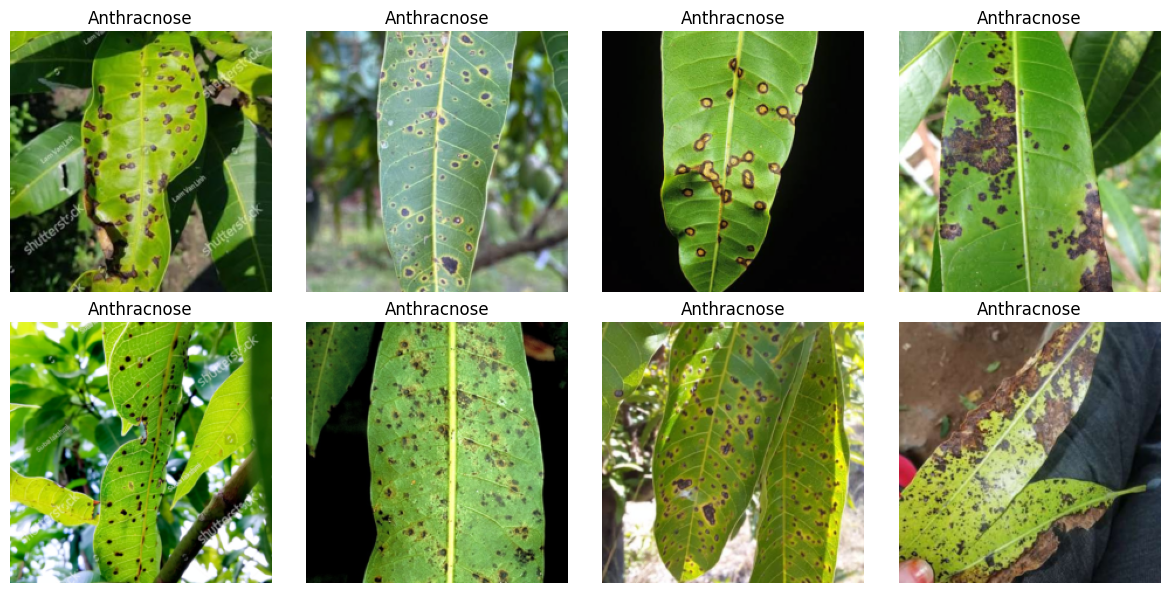

In [ ]:
# =====================================
# Dataset Summary
# =====================================

dataset_summary = pd.DataFrame({
    "Dataset": [
        "Train",
        "Validation",
        "Internal Test",
        "External Test"
    ],
    "Total Images": [
        len(train_dataset),
        len(val_dataset),
        len(test_dataset),
        len(external_dataset)
    ]
})

print(dataset_summary)

# =====================================
# Visualize External Images
# =====================================

import matplotlib.pyplot as plt
import numpy as np

images, labels = next(iter(external_loader))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):

    if i >= len(images):
        break

    # Reverse normalization
    img = images[i].permute(1, 2, 0).numpy()

    img = img * np.array(std) + np.array(mean)
    img = np.clip(img, 0, 1)

    ax.imshow(img)

    ax.set_title(
        class_names[labels[i].item()]
    )

    ax.axis("off")

plt.tight_layout()
plt.show()